----**SALES ANALYSIS PROJECT**----

**1. PROJECT OVERVIEW**

   This sales analysis project in Python focuses on understanding customer purchasing behavior and identifying sales trends using various columns.  Graphs are used to analyze sales performance, compare customer demographics, identify popular product categories, and understand regional sales distribution. This analysis helps businesses identify their target customers, discover high-performing products and regions, and make data-driven decisions to improve sales and business growth.

**2. IMPORT LIBRARIES**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.simplefilter("ignore")

**3. LOAD DATASET**

In [2]:
df=pd.read_excel(r"C:\Users\Namrata Vyavahare\Documents\Sales_analysis_EDA_project\project Data new.xlsx")

**4. BASIC EXPLORATORY DATA ANALYSIS**

**4.1 Dataset Preview**

In [3]:
df.head()

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount,Status,unnamed1
0,1002903,Sanskriti,P00125942,F,26-35,28,0,Maharashtra,Western,Healthcare,Auto,1,23952.0,NaN,NaN
1,1000732,Kartik,P00110942,F,26-35,35,1,Andhra Pradesh,Southern,Govt,Auto,3,23934.0,NaN,NaN
2,1001990,Bindu,P00118542,F,26-35,35,1,Uttar Pradesh,Central,Automobile,Auto,3,23924.0,NaN,NaN
3,1001425,Sudevi,P00237842,M,0-17,16,0,Karnataka,Southern,Construction,Auto,2,23912.0,NaN,NaN
4,1000588,Joni,P00057942,M,26-35,28,1,Gujarat,Western,Food Processing,Auto,2,23877.0,NaN,NaN


**4.2 Dataset Information**

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11251 entries, 0 to 11250
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   User_ID           11251 non-null  int64  
 1   Cust_name         11251 non-null  str    
 2   Product_ID        11251 non-null  str    
 3   Gender            11251 non-null  str    
 4   Age Group         11251 non-null  str    
 5   Age               11251 non-null  int64  
 6   Marital_Status    11251 non-null  int64  
 7   State             11251 non-null  str    
 8   Zone              11251 non-null  str    
 9   Occupation        11251 non-null  str    
 10  Product_Category  11251 non-null  str    
 11  Orders            11251 non-null  int64  
 12  Amount            11239 non-null  float64
 13  Status            0 non-null      float64
 14  unnamed1          0 non-null      float64
dtypes: float64(3), int64(4), str(8)
memory usage: 1.9 MB


**4.3 Missing Values**

In [5]:
df.isnull().sum()

User_ID                 0
Cust_name               0
Product_ID              0
Gender                  0
Age Group               0
Age                     0
Marital_Status          0
State                   0
Zone                    0
Occupation              0
Product_Category        0
Orders                  0
Amount                 12
Status              11251
unnamed1            11251
dtype: int64

**4.4 Unique Values**

In [6]:
df.State.unique()

<ArrowStringArray>
[     'Maharashtra',   'Andhra Pradesh',    'Uttar Pradesh',
        'Karnataka',          'Gujarat', 'Himachal Pradesh',
            'Delhi',   'Madhya Pradesh',        'Jharkhand',
           'Kerala',          'Haryana',            'Bihar',
        'Rajasthan',      'Uttarakhand',        'Telangana',
           'Punjab']
Length: 16, dtype: str

In [7]:
df.Occupation.unique()

<ArrowStringArray>
[     'Healthcare',            'Govt',      'Automobile',    'Construction',
 'Food Processing',          'Lawyer',       'IT Sector',           'Media',
         'Banking',          'Retail',     'Hospitality',        'Aviation',
     'Agriculture',         'Textile',        'Chemical']
Length: 15, dtype: str

In [8]:
df["Age Group"].unique()

<ArrowStringArray>
['26-35', '0-17', '18-25', '55+', '46-50', '51-55', '36-45']
Length: 7, dtype: str

**5. DATA CLEANING**

**5.1 Remove Unnecessary Columns**

In [9]:
df.drop(["Status","unnamed1"],axis=1,inplace=True)

**5.2 Rename Columns**

In [10]:
df.rename(columns={"Occupation":"Sector"},inplace=True)

**5.2 Convert Marital Status Entries**

In [11]:
df["Marital_Status"]=df["Marital_Status"].astype("str").str.replace("0","single")

In [12]:
df["Marital_Status"]=df["Marital_Status"].astype("str").str.replace("1","married")

**6. DATA VISUALIZATION**

In [13]:
df.head()

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Sector,Product_Category,Orders,Amount
0,1002903,Sanskriti,P00125942,F,26-35,28,single,Maharashtra,Western,Healthcare,Auto,1,23952.0
1,1000732,Kartik,P00110942,F,26-35,35,married,Andhra Pradesh,Southern,Govt,Auto,3,23934.0
2,1001990,Bindu,P00118542,F,26-35,35,married,Uttar Pradesh,Central,Automobile,Auto,3,23924.0
3,1001425,Sudevi,P00237842,M,0-17,16,single,Karnataka,Southern,Construction,Auto,2,23912.0
4,1000588,Joni,P00057942,M,26-35,28,married,Gujarat,Western,Food Processing,Auto,2,23877.0


**6.1 Count Plot (Gender and Zone wise Count)**

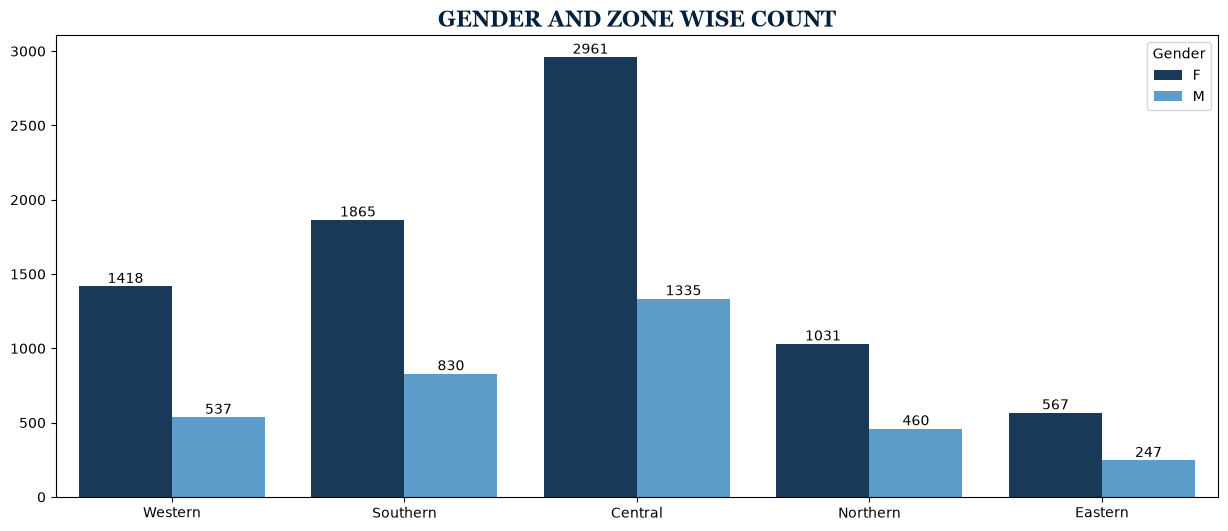

In [14]:
X1=["#0E3962", "#489FDD"]
plt.figure(figsize=(15,6))
data1=sns.countplot(x="Zone",data=df,hue="Gender",palette=X1)
for i in data1.containers:
    data1.bar_label(i)
plt.title("GENDER AND ZONE WISE COUNT",fontweight="bold", fontsize=16, family="georgia",color="#04203B")
plt.xlabel("")
plt.ylabel("")
plt.show()

**REPORT:** 
 Female customers outnumber male customers in every zone. The Central Zone has the highest customer count, with 2,961 female and 1,335 male customers, followed by the Southern Zone. The Eastern Zone has the lowest customer count, with 567 female and 247 male customers.

**6.2 Pie Chart (Zone wise Users)**

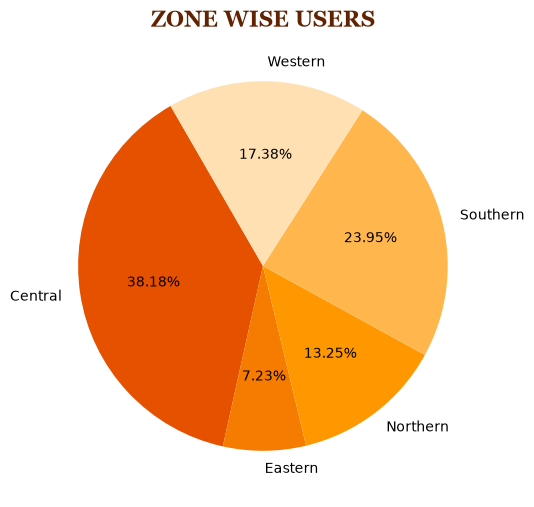

In [15]:
data2=df.groupby("Zone",as_index=False)["User_ID"].count()
X2=[ "#E65100", "#F57C00", "#FF9800", "#FFB74D", "#FFE0B2"]
plt.figure(figsize=(15,6))
plt.pie(data2["User_ID"],labels=data2["Zone"],autopct="%.2f%%",colors=X2,startangle=120)
plt.title("ZONE WISE USERS",fontweight="bold", fontsize=16, family="georgia",color="#612302")
plt.xlabel("")
plt.ylabel("")
plt.show()

**REPORT:** The Central and Southern zones together contribute approximately 62.13% of the total users, making them the major customer markets. Businesses can focus on these zones to maintain growth while introducing targeted marketing strategies to expand their customer base in the Eastern and Northern zones.

**6.3 Horizontal Bar Graph (Total Orders in Product Categories)**

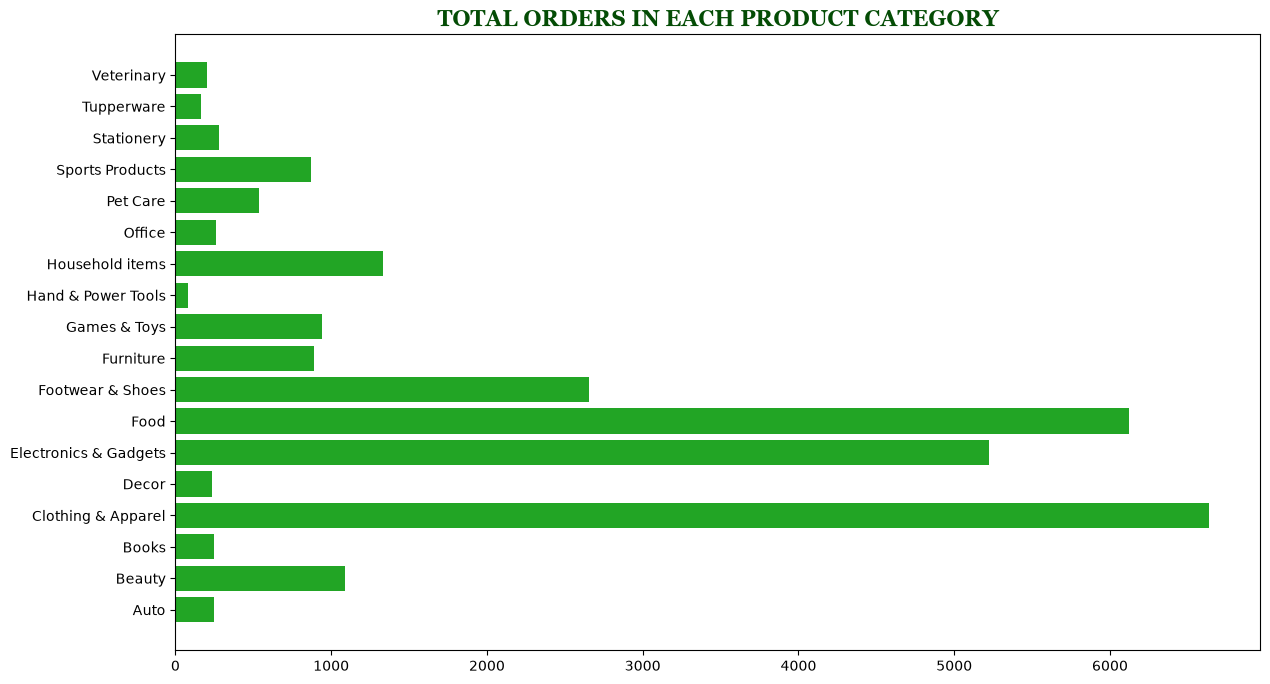

In [16]:
data6=df.groupby("Product_Category",as_index=False)["Orders"].sum()
X4=["#22A525"]
plt.figure(figsize=(14,8))
plt.barh(data6["Product_Category"],data6["Orders"],color=X4)
plt.title("TOTAL ORDERS IN EACH PRODUCT CATEGORY",fontweight="bold", fontsize=16, family="georgia",color="#044C05")
plt.xlabel("")
plt.ylabel("")
plt.show()

**REPORT:** Clothing & Apparel, Food, and Electronics & Gadgets are the most popular product categories. Businesses can prioritize these categories to maintain sales performance while using targeted promotions and marketing strategies to increase orders in less popular categories.

**6.4 Count Plot (Age-Group wise Marital Status Count)**

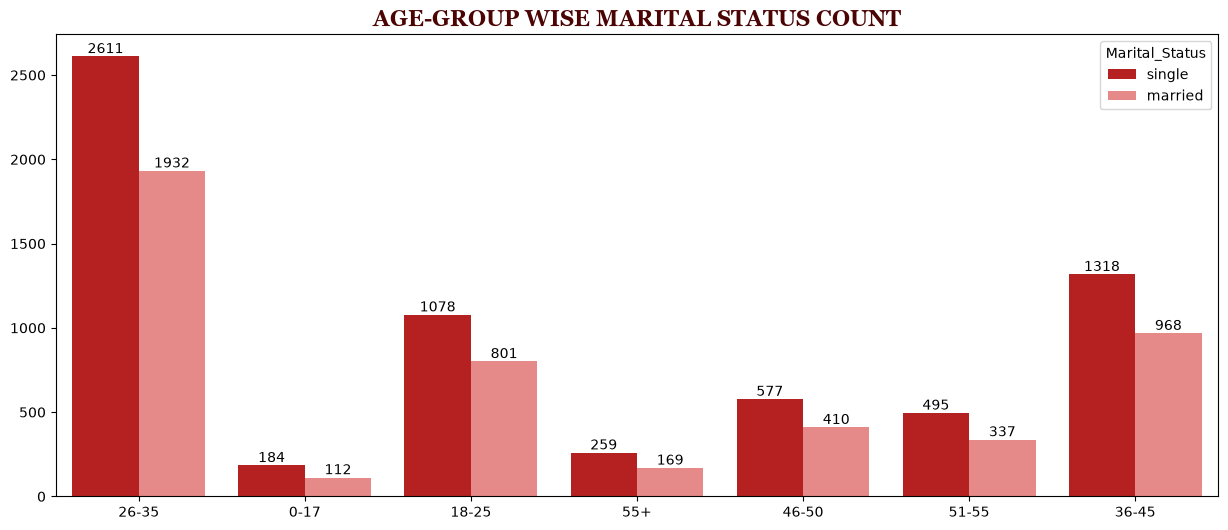

In [17]:
X3=[ "#CE0808", "#F47B79"]
plt.figure(figsize=(15,6))
data3=sns.countplot(x="Age Group",data=df,hue="Marital_Status",palette=X3)
for i in data3.containers:
    data3.bar_label(i)
plt.title("AGE-GROUP WISE MARITAL STATUS COUNT",fontweight="bold", fontsize=16, family="georgia",color="#4B0303")
plt.xlabel("")
plt.ylabel("")
plt.show()

**REPORT:** The data is concentrated mainly in the 26–35 and 36–45 age groups, and single individuals consistently outnumber married individuals across all age categories.

****6.5 Line Plot (Total Amount by each Sector)**

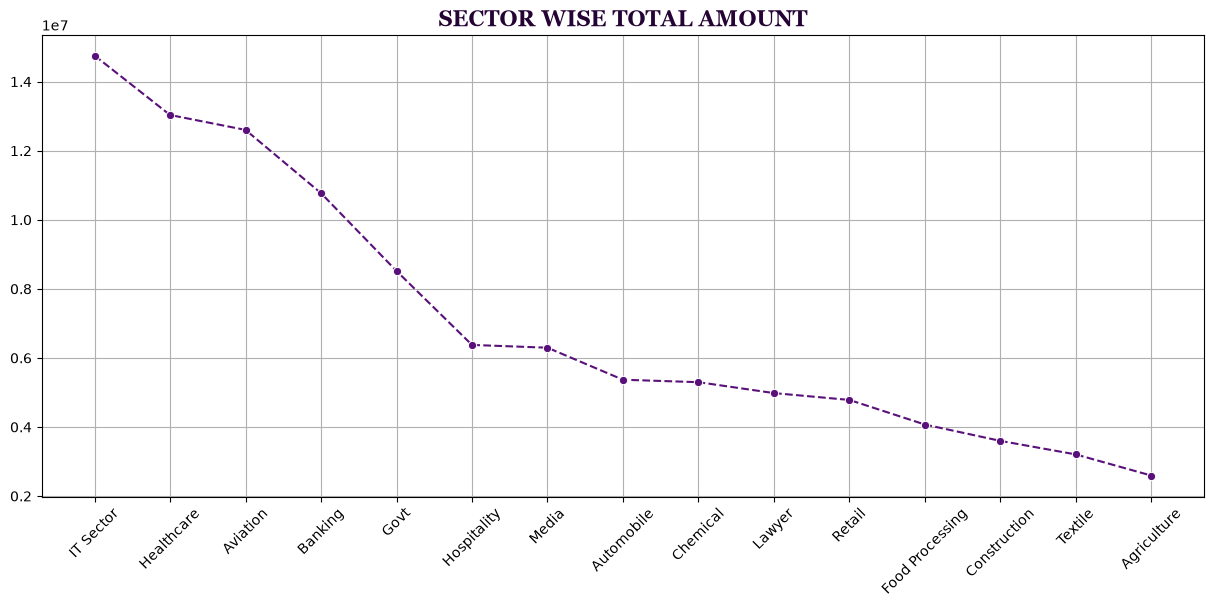

In [18]:
data4=df.groupby("Sector",as_index=False)["Amount"].sum().sort_values(by="Amount",ascending=False)
plt.figure(figsize=(15,6))
sns.lineplot(x="Sector",y="Amount",data=data4,marker="o",linestyle="--",color="#5A107A")
plt.title("SECTOR WISE TOTAL AMOUNT",fontweight="bold", fontsize=16, family="georgia",color="#250334")
plt.xlabel("")
plt.ylabel("")
plt.grid()
plt.xticks(rotation=45)
plt.show()

**REPORT:** he distribution shows a clear downward trend, with the IT sector dominating the total amount and the Agriculture sector recording the lowest value

**6.6 Bar Plot (Top 10 states with maximum Orders)**

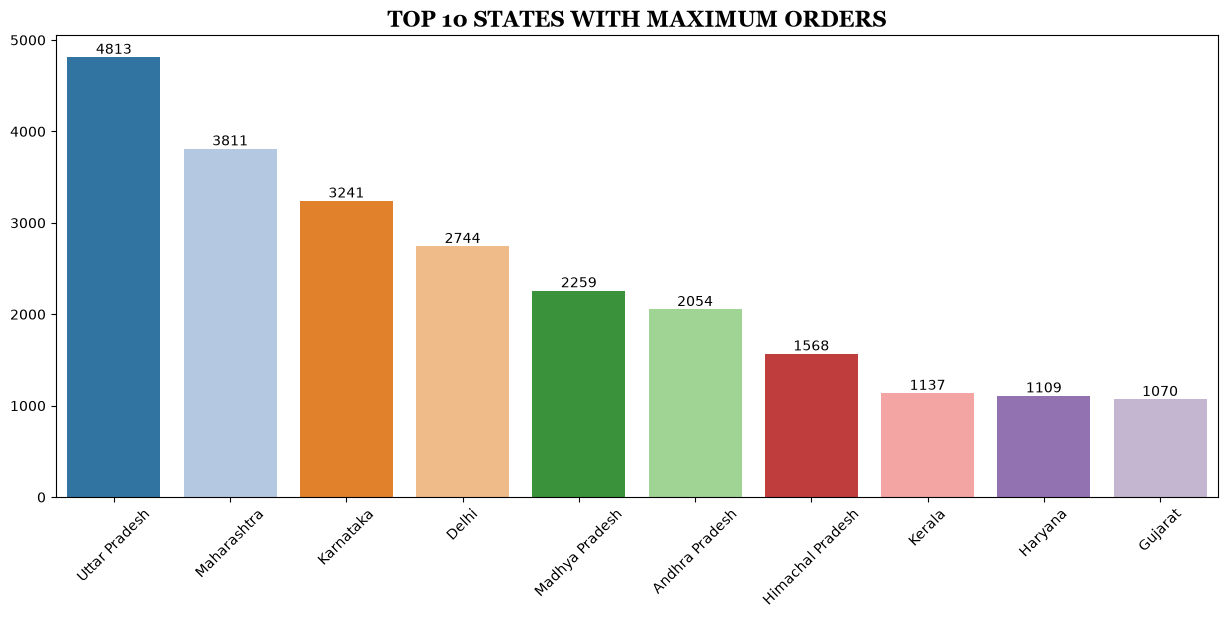

In [19]:
data5=df.groupby("State",as_index=False)["Orders"].sum().sort_values(by="Orders",ascending=False).head(10)
plt.figure(figsize=(15,6))
data_5=sns.barplot(x="State",y="Orders",data=data5,palette="tab20")
for i in data_5.containers:
    data_5.bar_label(i)
plt.title("TOP 10 STATES WITH MAXIMUM ORDERS",fontweight="bold", fontsize=16, family="georgia")
plt.xlabel("")
plt.ylabel("")
plt.xticks(rotation=45)
plt.show()

**REPORT:** Uttar Pradesh leads significantly in order volume, while Maharashtra and Karnataka are also major contributors. The distribution indicates that orders are concentrated mainly in a few high-performing states.

**6.7 Line Plot (Total Amount by each State)**

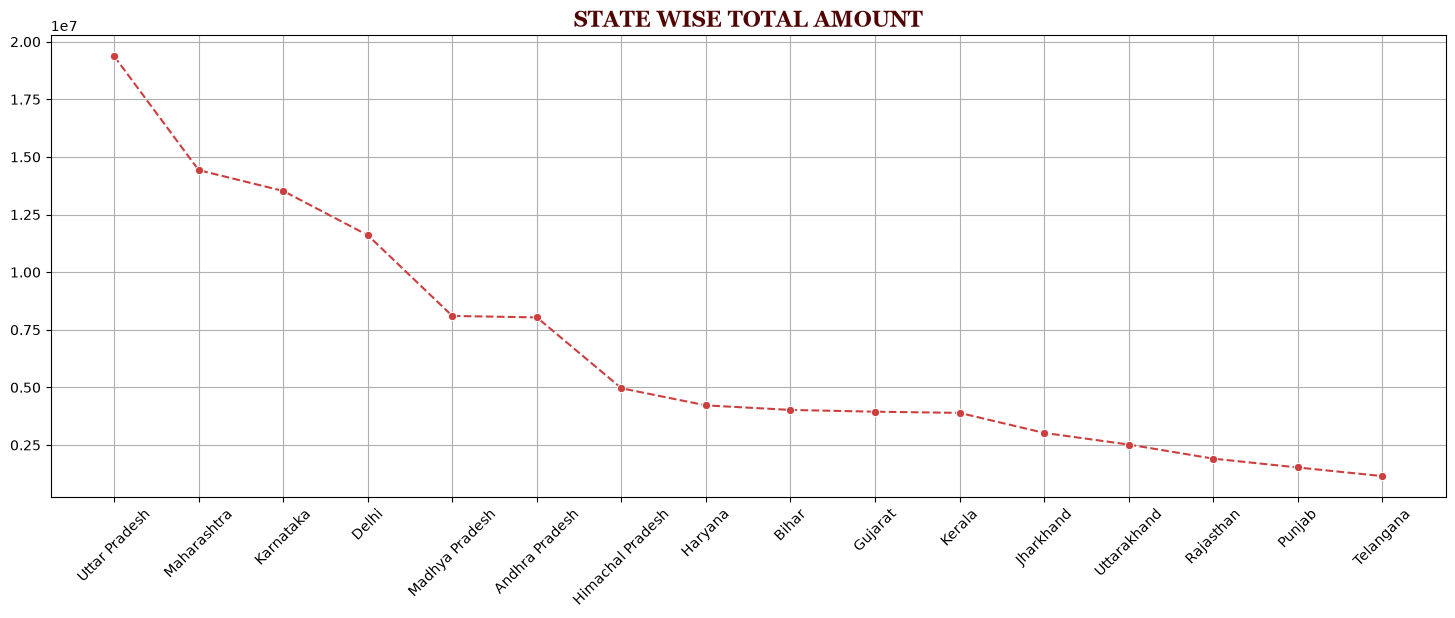

In [20]:
data7=df.groupby("State",as_index=False)["Amount"].sum().sort_values(by="Amount",ascending=False)
plt.figure(figsize=(18,6))
sns.lineplot(x="State",y="Amount",data=data7,marker="o",linestyle="--",color="#CD3F3F")
plt.title("STATE WISE TOTAL AMOUNT",fontweight="bold", fontsize=16, family="georgia",color="#500404")
plt.xlabel("")
plt.ylabel("")
plt.grid()
plt.xticks(rotation=45)
plt.show()

**REPORT:** Uttar Pradesh leads clearly well ahead of every other state. Maharashtra, Karnataka and Delhi form a strong second group. Together with Uttar Pradesh, these four states account for the bulk of the total. Madhya Pradesh and Andhra Pradesh are nearly equal.
After Andhra Pradesh, the amount falls by almost half to Himachal Pradesh. Telangana is lowest.

****6.8 Pie Chart (Total Orders in each Age-Group)**

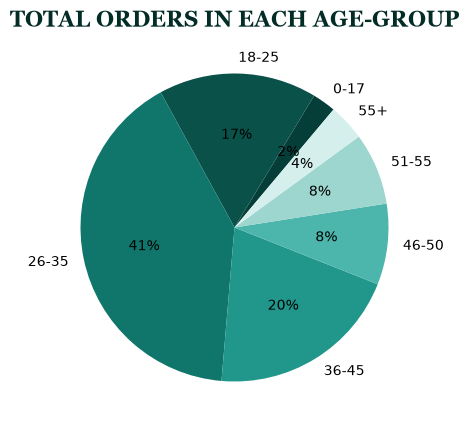

In [21]:
data8=df.groupby("Age Group",as_index=False)["Orders"].sum()
X5= ["#053D38", "#095149", "#10766B", "#21968A","#4DB6AC", "#9DD5CF", "#D5EFED"]
plt.figure(figsize=(12,5))
plt.pie(data8["Orders"],labels=data8["Age Group"],autopct="%.f%%",colors=X5,startangle=50)
plt.title("TOTAL ORDERS IN EACH AGE-GROUP",fontweight="bold", fontsize=16, family="georgia",color="#032C27")
plt.xlabel("")
plt.ylabel("")
plt.show()

**REPORT:** The above pie chart depicts the total orders in each age group. It clearly shows that the users between 26yrs and 35yrs has the most orders,whereas, age group 18yrs-25yrs and 36yrs-45yrs has almost the same percentage of orders. the least orders are ordered by the people under age 18.

**6.9 Bar Chart (Count of Sectors in each Age-Group)**

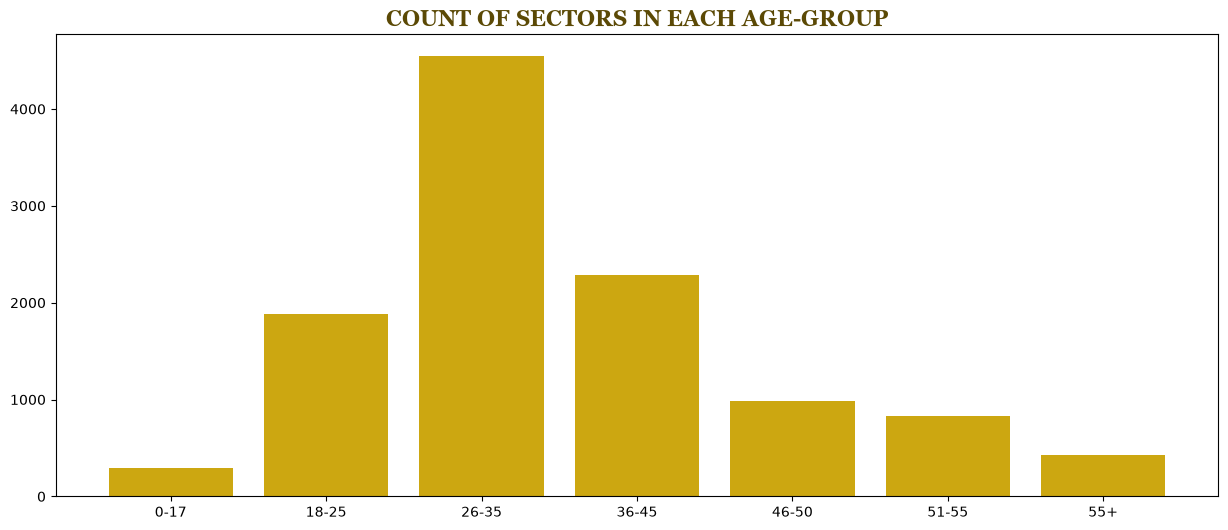

In [22]:
data9=df.groupby("Age Group",as_index=False)["Sector"].count()
X6=[ "#CCA711"]
plt.figure(figsize=(15,6))
plt.bar(data9["Age Group"],data9["Sector"],color=X6)
plt.title("COUNT OF SECTORS IN EACH AGE-GROUP",fontweight="bold", fontsize=16, family="georgia",color= "#5B4905")
plt.xlabel("")
plt.ylabel("")
plt.show()


**REPORT:** The above graph shows the count of sectors in each age group. It clarifies that the age group 26yrs-35yrs has the maximum number of sectors which is above 4000. Age group 18yrs-25yrs and 36yrs-45yrs has almost the same count of sectores. The least sectors are are in the agre group under 18.

**6.10 Bar Plot (Sectors with it's Total Users)**

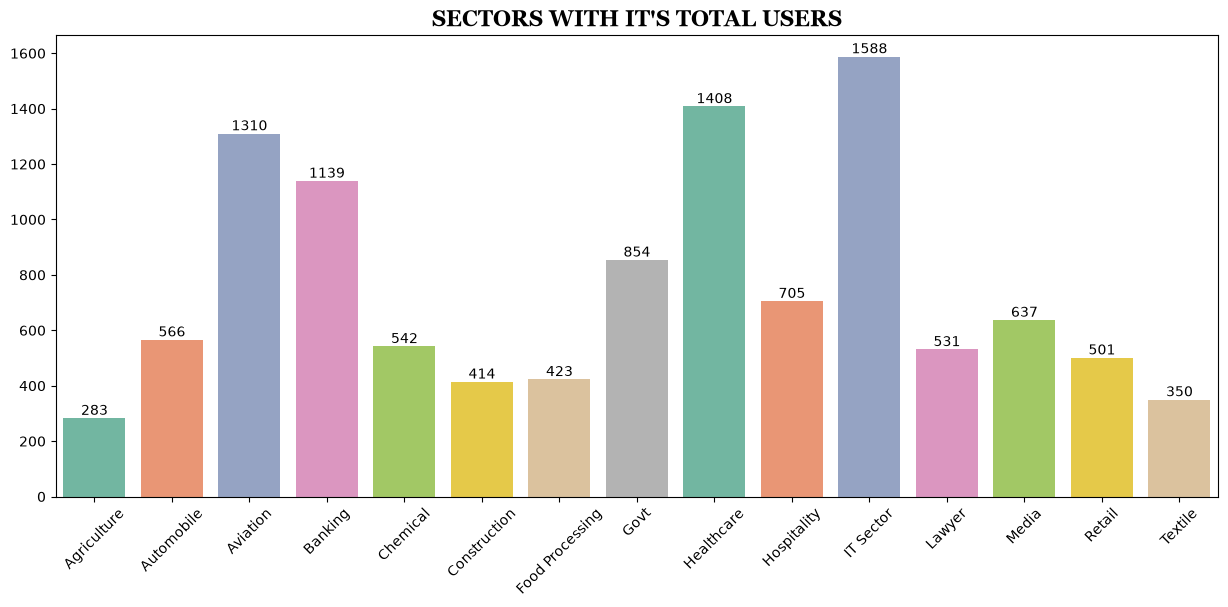

In [23]:
data10=df.groupby("Sector",as_index=False)["User_ID"].count()
plt.figure(figsize=(15,6))
data_10=sns.barplot(x="Sector",y="User_ID",data=data10,palette="Set2")
for i in data_10.containers:
    data_10.bar_label(i)
plt.title("SECTORS WITH IT'S TOTAL USERS",fontweight="bold", fontsize=16, family="georgia")
plt.xlabel("")
plt.ylabel("")
plt.xticks(rotation=45)
plt.show()

**REPORT:** The bar chart shows total users across 15 sectors. Values range from 283 (Agriculture) to 1,588 (IT Sector), a spread of more than 5x. IT Sector, Healthcare and Aviation lead clearly. Banking is the only sector in the 1,000+ range after the top three. Government follows as a mid-high performer. Hospitality, Media, Automobile, Chemical, Lawyer and Retail sit between about 500 and 700. Construction, Food Processing, Textile and Agriculture trail the rest.

**HISTPLOT (AGE COUNT)**

<Axes: xlabel='Age', ylabel='Count'>

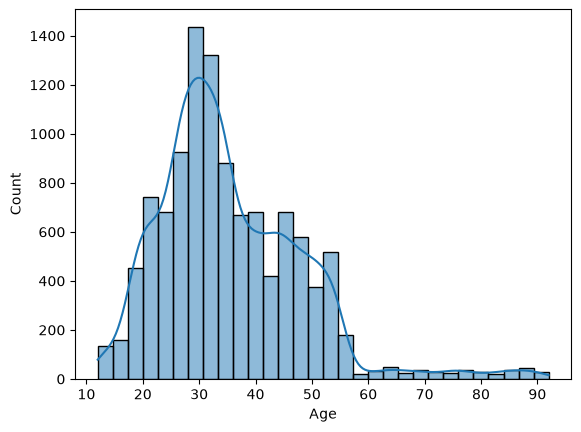

In [24]:
sns.histplot(x="Age",data=df,bins=30,kde=True)

**Step 1: Shape of the data**

In [26]:
df.shape

(11251, 13)

**Step 2: Calculating the mean, median and mode**

In [27]:
print("Mean--->",df["Age"].mean())
print("----------------------------")
print("Median--->",df["Age"].median())
print("----------------------------")
print("Mode--->",df["Age"].mode())

Mean---> 35.421207003821884
----------------------------
Median---> 33.0
----------------------------
Mode---> 0    30
Name: Age, dtype: int64


**CALCULATING OUTLIERS**

In [ ]:
outliers_set1=df[df["Age"]>57]

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Sector,Product_Category,Orders,Amount
7,1002092,Shivangi,P00273442,F,55+,61,single,Maharashtra,Western,IT Sector,Auto,1,NaN
24,1000900,Skaria,P00317842,M,55+,83,single,Karnataka,Southern,Automobile,Auto,3,23513.0
38,1002520,Mike,P00310342,M,55+,72,married,Himachal Pradesh,Northern,Media,Auto,4,23267.0
124,1001896,Brittain,P00117142,M,55+,66,single,Uttar Pradesh,Central,Govt,Footwear & Shoes,2,20853.0
197,1001736,Martinez,P00227942,M,55+,72,married,Uttar Pradesh,Central,Textile,Footwear & Shoes,2,20603.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
11148,1002002,Maureen,P00177442,M,55+,89,single,Telangana,Southern,Healthcare,Office,1,777.0
11162,1005223,Nandita,P00059642,F,55+,69,single,Delhi,Central,IT Sector,Office,4,766.0
11192,1002368,Sonia,P00329642,M,55+,67,single,Karnataka,Southern,Media,Office,3,744.0
11208,1002121,Prescott,P00344042,F,55+,64,single,Uttarakhand,Central,Healthcare,Pet Care,1,688.0


**REPORT:**

The peak is at about 28 to 34, and there is a cliff after 56. It clarifies that the histplot is right skewed. We can prove that it is a  right skewed histplot as we know it has mean>median>mode.
To make it clear or to prove we have performed above few steps.
We can also check the approximate number of outliers is 406.

**BOX PLOT (AMOUNT)**

<Axes: xlabel='Amount'>

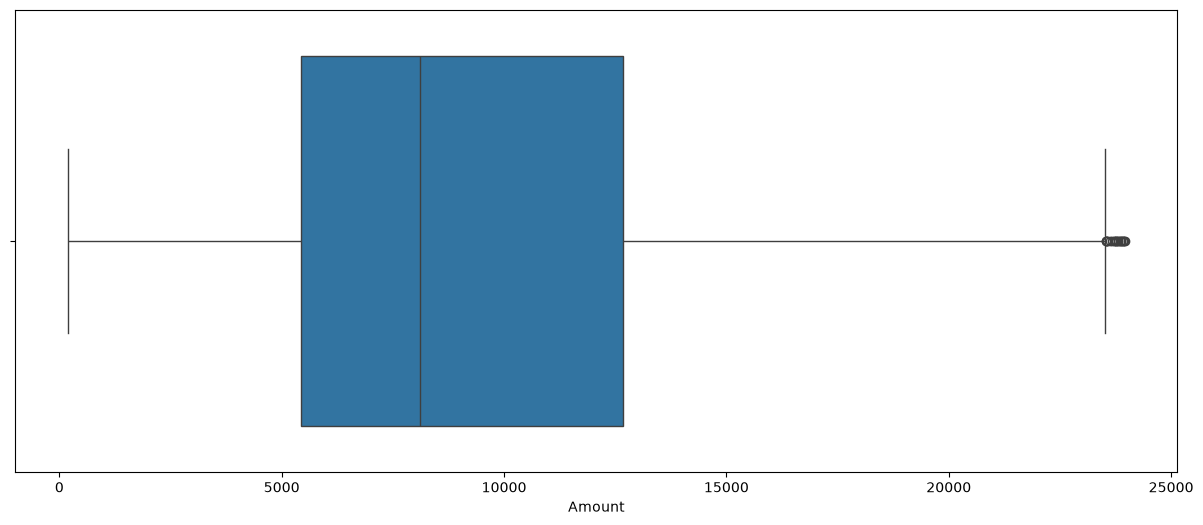

In [30]:
plt.figure(figsize=(15,6))
sns.boxplot(x="Amount",data=df)

**Step 1: Calculating 50% of data**

In [31]:
11251/2   #Calculating 50% of data

5625.5

**Step 2: Calculating the IQR**

In [ ]:
IQR=df[(df["Amount"]>5500) & (df["Amount"]<12800)]

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Sector,Product_Category,Orders,Amount
2735,1002826,Sagar,P00362342,F,36-45,37,single,Delhi,Central,Agriculture,Footwear & Shoes,4,12799.0
2736,1001824,Goldwyn,P00110942,M,18-25,18,married,Karnataka,Southern,Agriculture,Tupperware,4,12799.0
2737,1001639,Charika,P00016042,F,26-35,35,married,Delhi,Central,Construction,Footwear & Shoes,4,12797.0
2738,1004238,Dona,P00136542,F,36-45,39,single,Delhi,Central,IT Sector,Footwear & Shoes,1,12796.0
2739,1000718,Ed,P00036842,F,18-25,24,single,Karnataka,Southern,Retail,Games & Toys,3,12796.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8356,1001607,Kampe,P00225042,F,46-50,50,single,Uttar Pradesh,Central,Banking,Sports Products,1,5530.0
8357,1001804,Ishit,P00093242,F,26-35,35,single,Haryana,Northern,Retail,Sports Products,3,5526.0
8358,1000307,Andreada,P00308242,F,51-55,55,married,Maharashtra,Western,Healthcare,Sports Products,3,5514.0
8359,1002056,Ankur,P00184242,F,26-35,30,married,Haryana,Northern,Automobile,Sports Products,1,5511.0


**CALCULATING OUTLIERS**

In [ ]:
outliers_set2=df[df["Amount"]>23500]

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Sector,Product_Category,Orders,Amount
0,1002903,Sanskriti,P00125942,F,26-35,28,single,Maharashtra,Western,Healthcare,Auto,1,23952.00
1,1000732,Kartik,P00110942,F,26-35,35,married,Andhra Pradesh,Southern,Govt,Auto,3,23934.00
2,1001990,Bindu,P00118542,F,26-35,35,married,Uttar Pradesh,Central,Automobile,Auto,3,23924.00
3,1001425,Sudevi,P00237842,M,0-17,16,single,Karnataka,Southern,Construction,Auto,2,23912.00
4,1000588,Joni,P00057942,M,26-35,28,married,Gujarat,Western,Food Processing,Auto,2,23877.00
5,1000588,Joni,P00057942,M,26-35,28,married,Himachal Pradesh,Northern,Food Processing,Auto,1,23877.00
6,1001132,Balk,P00018042,F,18-25,25,married,Uttar Pradesh,Central,Lawyer,Auto,4,23841.00
8,1003224,Kushal,P00205642,M,26-35,35,single,Uttar Pradesh,Central,Govt,Auto,2,23809.00
9,1003650,Ginny,P00031142,F,26-35,26,married,Andhra Pradesh,Southern,Media,Auto,4,23799.99
10,1003829,Harshita,P00200842,M,26-35,34,single,Delhi,Central,Banking,Auto,1,23770.00


**REPORT**

The median is about ₹8,100 and the middle half runs from about ₹5,400 to ₹12,700. Outliers appear only at the high end, from about ₹23,500 to ₹24,000. To prove it we have performed two steps. In step 1 we have calculated the 50% of data which is approximately eual to the IQR calculated in step 3.
Outliers are also calculated and they are nearly 24.

**SCATTER PLOT (AGE vs AMOUNT)**

<Axes: xlabel='Age', ylabel='Amount'>

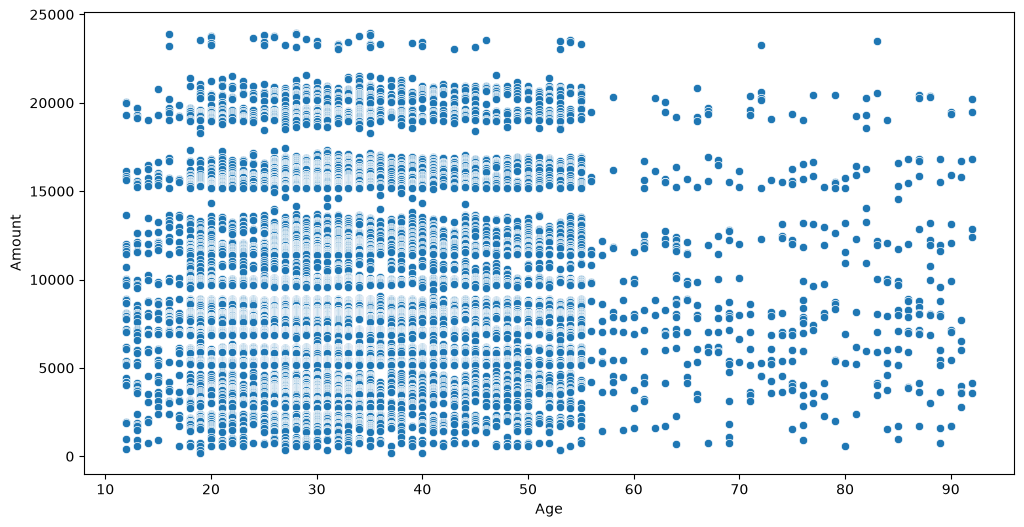

In [35]:
plt.figure(figsize=(12,6))
sns.scatterplot(x="Age",y="Amount",data=df)

**REPORT**

Age has no visible effect on Amount, and amounts stack in distinct bands. The data thins out sharply after about 56.
This prooves the hisplot and boxplot of this project. The outliers that we calculated for histplot and boxplot matches the outliers of the above scatterplot

**HEAT MAP**

In [38]:
pivot_table1=df.pivot_table(values="Orders",columns="Gender",index="State",aggfunc="sum")

<Axes: xlabel='Gender', ylabel='State'>

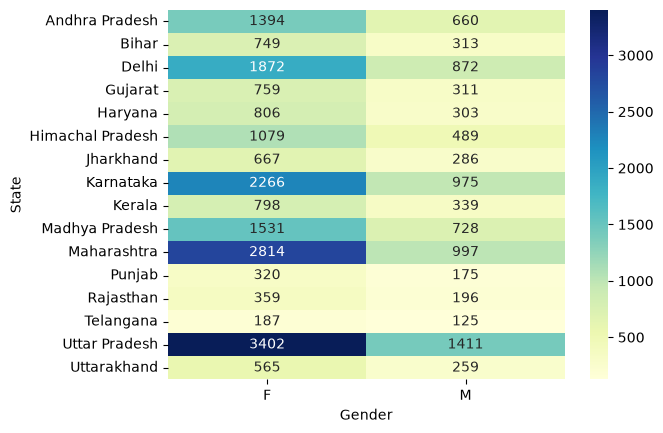

In [39]:
sns.heatmap(pivot_table1,annot=True,fmt="0.0f",cmap="YlGnBu")

**REPORT**

Women outnumber men in every state. Uttar Pradesh, Maharashtra, Karnataka and Delhi hold over half of all customers.

**7. CONCLUSION**

**Core customer:** A single woman aged 26-35, working in IT, Healthcare, Aviation or Banking.

**Top locations:** Uttar Pradesh, Maharashtra, Karnataka and Delhi lead in orders and amount. Central zone has the most users (~38%), 
               and Eastern the      fewest (~7%).

**Top categories:** Clothing & Apparel, Food and Electronics & Gadgets.

**Risk:** Sales depend heavily on a few states, ages and categories.

**Opportunity:** Grow the Eastern zone, male customers, the 46+ age groups and weak sectors


It says the typical customer is a woman in her late 20s to mid 30s from Uttar Pradesh, Maharashtra, Karnataka or Delhi, spending about ₹8,000 per purchase. It also recommends checking the 55+ data gap and the histogram-versus-heatmap count mismatch before acting on the numbers.
It concludes that the only outliers in Amount are a few high values, from about ₹23,500 to ₹24,000. They look like a premium price tier rather than errors, so they should be kept and reported as a premium segment. I also noted that customers over about 60 are outliers in age, but the sharp drop at 56.

**8. CLEAN DATASET**

In [25]:
df.to_csv("Clean data file.csv",index=False)